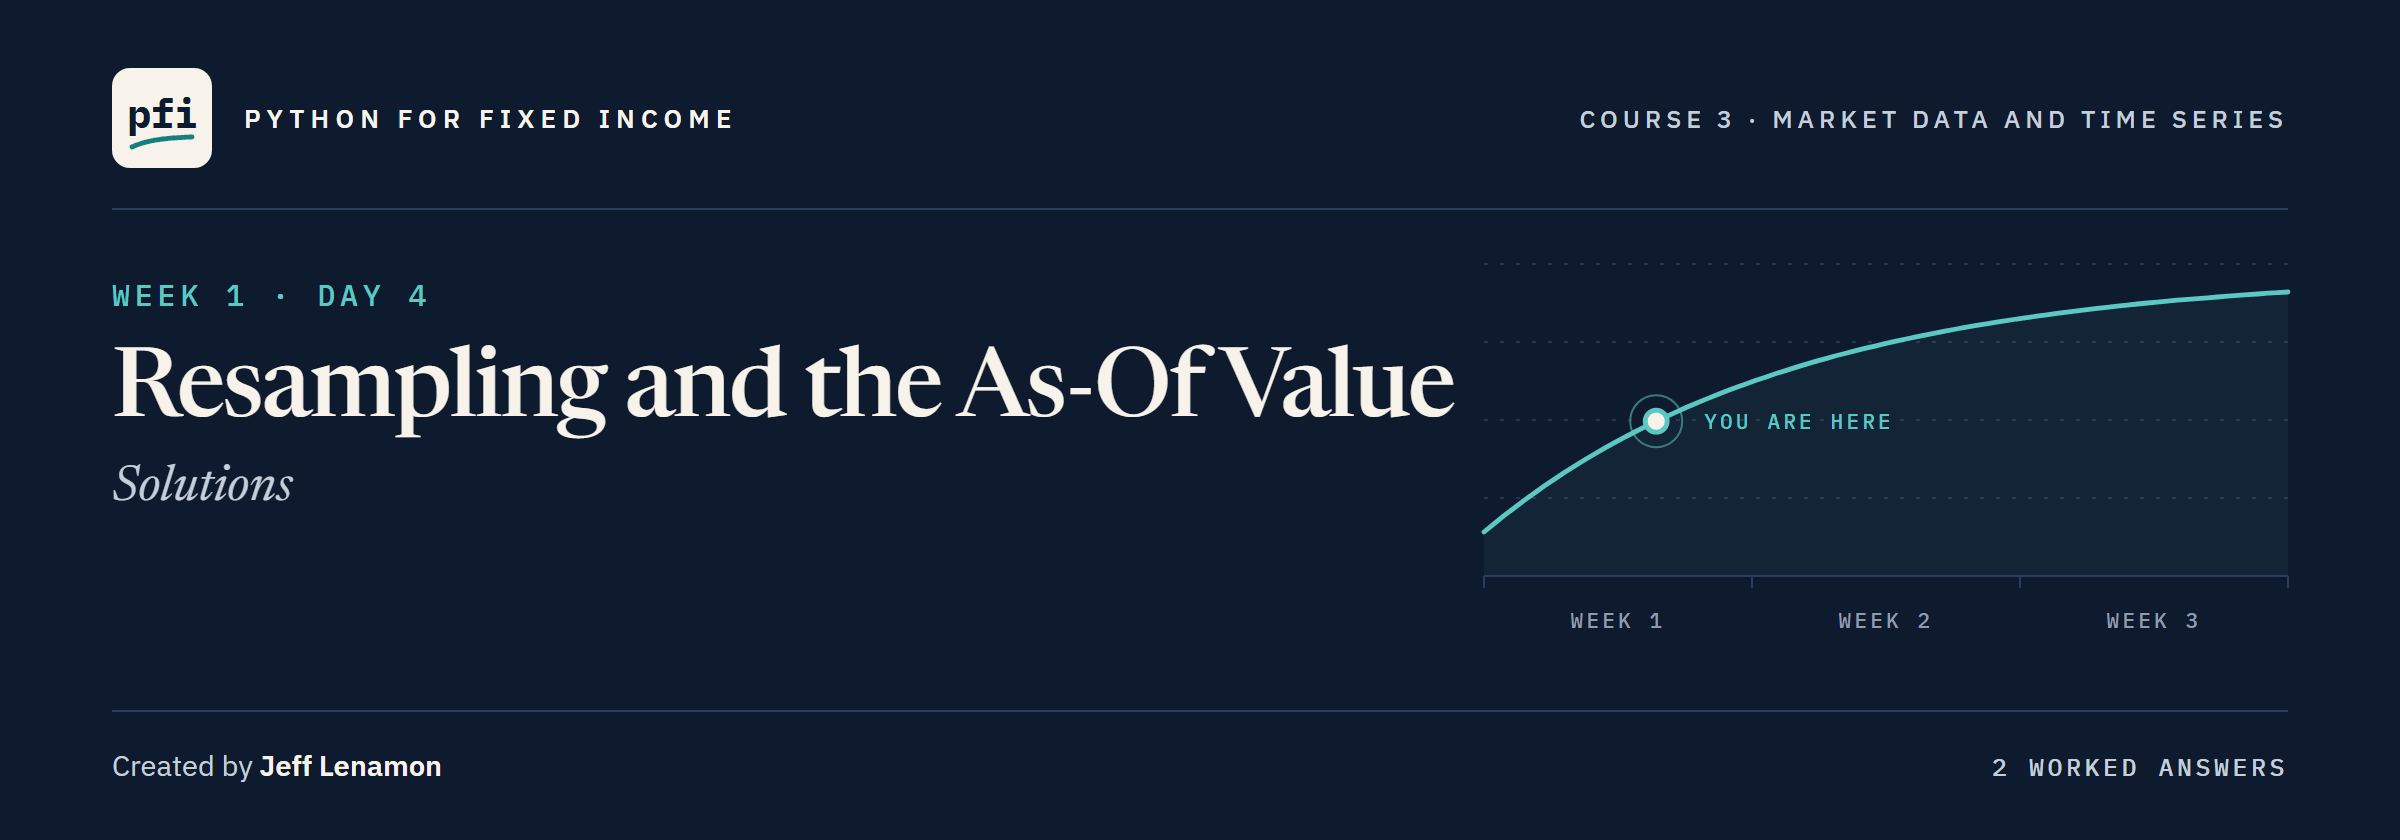

# Resampling and the As-Of Value: Solutions

Week 1, Day 4. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week1/day4/04_resampling_and_the_as_of_value_solutions.ipynb)

## Exercises

Run the next cells first: the work folder, with the module and tests as this notebook leaves them, the imports, `check`, and the Treasury file.

No key is needed.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}course03_market_data/start_of_day/start_day.py
from start_day import start_day

# a new work folder: the data files, Course 2's bondmath.py, and marketdata.py and its tests
# as notebook 04 ends.
# To start the day again, restart the kernel and run all cells.
work = start_day(4, after=4)

Work folder pfi_course3_04_k4w7q2xr: 4 data files, Course 2's bondmath.py, marketdata.py as notebook 04 left it, 4 commits


In [2]:
import importlib

import pandas as pd

import marketdata as md

print('value_as_of is in the module:', 'value_as_of' in dir(md))

value_as_of is in the module: True


In [3]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [4]:
# the Treasury file and its 10 Yr, as in the lesson
treasury = pd.read_csv('treasury_par_yields.csv', parse_dates=['date'], index_col='date',
                       float_precision='round_trip')
ten = treasury['10 Yr']

### Exercise 1

In [5]:
september_weeks = md.last_per_period(treasury['5 Yr'], 'W-FRI').loc['2026-09']
ex1_values = september_weeks.tolist()
ex1_labels = list(september_weeks.index.strftime('%Y-%m-%d'))
print(ex1_values, ex1_labels)

[4.54, 4.78, 4.86, 4.98] ['2026-09-04', '2026-09-11', '2026-09-18', '2026-09-25']


In [6]:
check('Exercise 1 the weekly levels', ex1_values, [4.54, 4.78, 4.86, 4.98])
check('Exercise 1 the labels', ex1_labels,
      ['2026-09-04', '2026-09-11', '2026-09-18', '2026-09-25'])

Exercise 1 the weekly levels: correct
Exercise 1 the labels: correct


The week ending Friday 2 October has its last row in October, so September has four.

### Exercise 2

In [7]:
# prediction: the market day before each, Friday 16 January, Friday 22 May, Thursday 2 July
ex2_results = [md.value_as_of(ten, day) for day in ['2026-01-19', '2026-05-25', '2026-07-03']]
for as_of_date, value in ex2_results:
    print(as_of_date.date(), value)

2026-01-16 4.24
2026-05-22 4.56
2026-07-02 4.49


In [8]:
check('Exercise 2 the as-of values', ex2_results,
      [(pd.Timestamp('2026-01-16'), 4.24), (pd.Timestamp('2026-05-22'), 4.56),
       (pd.Timestamp('2026-07-02'), 4.49)])

Exercise 2 the as-of values: correct


Each holiday takes the market day before it, and the function says which.

### Exercise 3

In [9]:
%%writefile -a marketdata.py


def month_end_table(curve: pd.DataFrame, tenors: list[str]) -> pd.DataFrame:
    """Month-end levels of the chosen tenors: one row per calendar month, labelled by its last market date.

    Units: unchanged (percent for Treasury yields). Convention: the last row of each month, taken with
    last_per_period, so a month that ends on a weekend or a holiday is labelled by its last market day.
    Raises ValueError naming any tenor that is not a column of curve.
    """
    absent = [tenor for tenor in tenors if tenor not in curve.columns]
    if absent:
        raise ValueError(f"not columns of the curve: {absent}")
    return last_per_period(curve[tenors], "ME")

Appending to marketdata.py


In [10]:
%%writefile -a test_marketdata.py


def test_month_end_table_labels_and_columns():
    table = md.month_end_table(read_treasury(), ["5 Yr", "30 Yr"])
    assert list(table.columns) == ["5 Yr", "30 Yr"]
    # September 2026 is labelled by its last market date, May 2026 by Friday 29 (the 31st is a Sunday)
    assert table.loc["2026-09"].index[0] == pd.Timestamp("2026-09-30")
    assert pd.Timestamp("2026-05-29") in table.index
    with pytest.raises(ValueError):
        md.month_end_table(read_treasury(), ["11 Yr"])

Appending to test_marketdata.py


In [11]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..................                                                       [100%]
18 passed in 0.50s



In [12]:
# the file changed, so reload before calling the new function
importlib.reload(md)
ex3_row = md.month_end_table(treasury, ['5 Yr', '30 Yr']).loc['2026-09-30'].tolist()
print(ex3_row)

[5.09, 5.64]


In [13]:
check('Exercise 3 the September 2026 row', ex3_row, [5.09, 5.64])

Exercise 3 the September 2026 row: correct


### Exercise 4: AI check

The bug: `.first()` keeps the first observation of each month, the wrong edge.
For September 2026 it returns 4.79, the open on 2026-09-01, under the label 2026-09-30: a plausible number under a label that looks right.
The fix keeps the last observation with its own date, `md.last_per_period(series, 'ME')`.

In [14]:
# written for this course in the style of an AI assistant's answer, now fixed
def month_end_levels(series):
    """Month-end levels of a daily yield series: one value per calendar month.

    Units: unchanged (percent for a yield). Convention: each month's value is its month-end
    level, the observation on the last market day of the month. A month that ends on a
    weekend or a holiday takes the value of its last market day.
    """
    # the fix: the last observation of each month, labelled by its own date
    return md.last_per_period(series, 'ME')

In [15]:
# the test, written from the docstring before the code is trusted
levels = month_end_levels(ten)
assert levels.loc['2026-09-30'] == 5.29, f"September 2026 is {levels.loc['2026-09-30']}, not 5.29"
print('September 2026 is 5.29 percent, its month-end level')

September 2026 is 5.29 percent, its month-end level


In [16]:
ex4_september = month_end_levels(ten).loc['2026-09-30']
ex4_months = len(month_end_levels(ten))
check('Exercise 4 September 2026', ex4_september, 5.29)
check('Exercise 4 the number of months', ex4_months, 142)

Exercise 4 September 2026: correct
Exercise 4 the number of months: correct


Keep the test: in your test file, one known month guards the edge for good.

[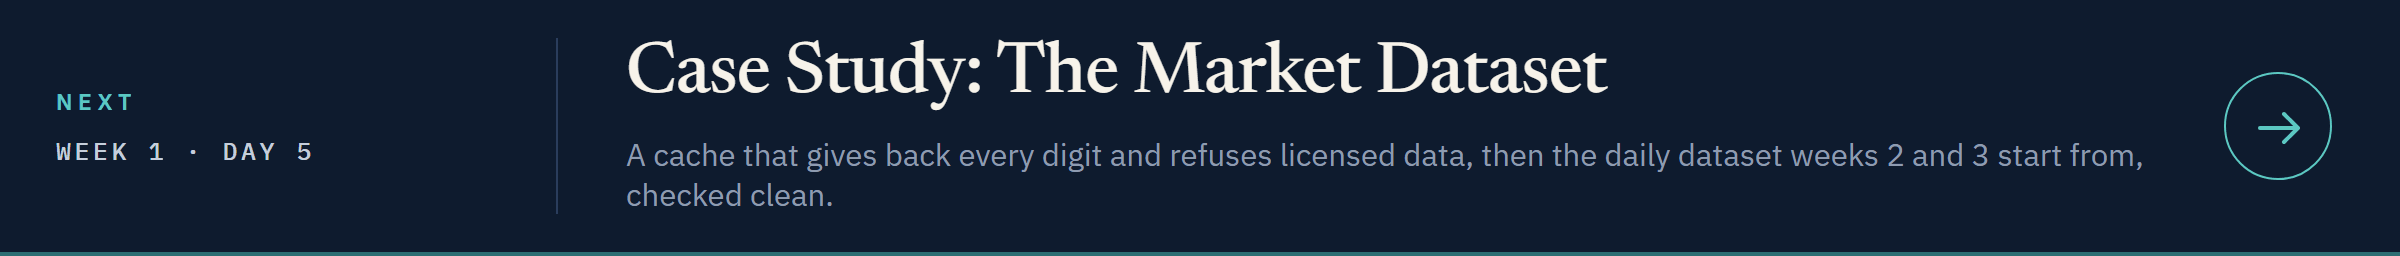](../day5/05_case_study_the_market_dataset.ipynb)

[Open Day 5 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week1/day5/05_case_study_the_market_dataset.ipynb)